In [8]:
import tarfile

from matplotlib.pyplot import colorbar

housing_tar = "../data/data_for_real_estate/housing.tar"
extract_dir = "../data/data_for_real_estate/"

with tarfile.open(housing_tar) as tar:
    tar.extractall(extract_dir)
    
import os
print(os.listdir(extract_dir))

['housing.csv', 'housing.tar']


In [9]:
import pandas as pd

housing_path = os.path.join(extract_dir, "housing.csv")
housing_data = pd.read_csv(housing_path)
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [10]:
housing_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [11]:
housing_data["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

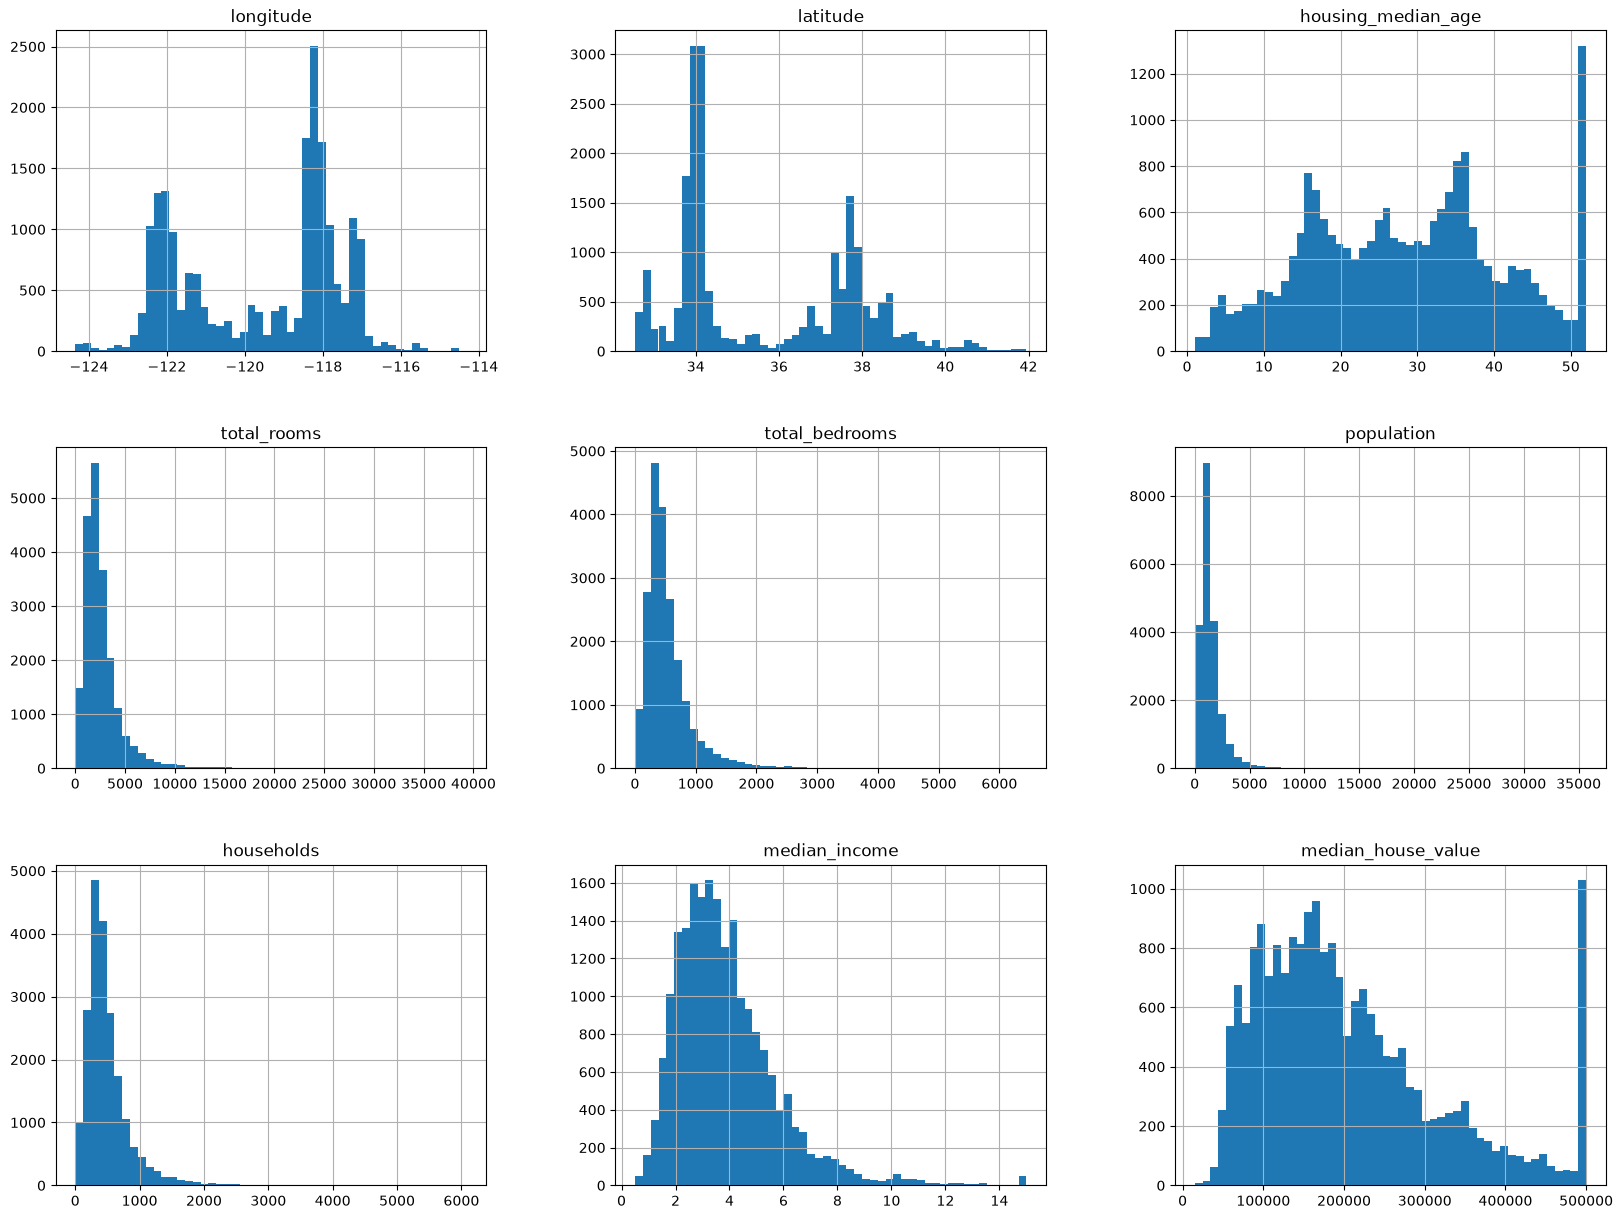

In [12]:
import matplotlib.pyplot as plt

housing_data.hist(bins=50, figsize=(20,15))
plt.show()

In [15]:
import numpy as np

def split_test_data(data, test_ratio):
    shuffled_indicies = np.random.permutation(len(data))
    test_size = int(len(data) * test_ratio)
    test_data = shuffled_indicies[:test_size]
    train_data = shuffled_indicies[test_size:]
    return data.iloc[train_data], data.iloc[test_data]

train_set, test_set = split_test_data(housing_data, 0.2)
len(train_set)

16512

In [17]:
#hash ID 

from zlib import crc32

def test_set_check(ID, test_ratio):
    return crc32(np.int64(ID)) & 0xffffffff < test_ratio * 2**32 
    #np.int64(ID) → ID'yi 64-bit tamsayıya çevirir (crc32 fonksiyonu byte benzeri bir veri beklediği için, numpy'nin int64 tipi bunu uygun formatta sağlar).
    #crc32(...) → bu sayı için bir checksum/hash üretir. Aynı ID her zaman aynı hash değerini verir (deterministik), yani rastgelelik yok — tamamen ID'ye bağlı.

housing_with_id = housing_data.reset_index()

def split_by_id(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: test_set_check(id_, test_ratio))
    return data.loc[~in_test_set],data.iloc[in_test_set]

train_set, test_set = split_by_id(housing_with_id, 0.2, "index")  

len(train_set)

16512

In [27]:
housing_data["income_cat"] = pd.cut(housing_data["median_income"],
                                    bins=[0. , 1.5, 3.0, 4.5, 6. , np.inf],
                                    labels=[1,2,3,4,5])


In [30]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(housing_data, housing_data["income_cat"]):
    strat_training_set = housing_data.loc[train_index]
    strat_test_set = housing_data.loc[test_index]
    
for set_ in (strat_training_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)
    

In [31]:
housing_data = strat_training_set.copy()

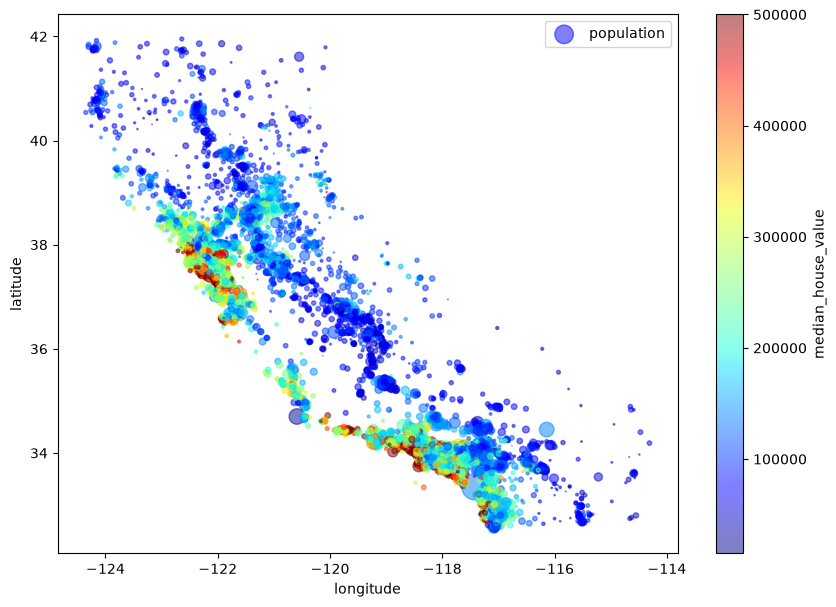

In [36]:
housing_data.plot(x="longitude", y="latitude", kind="scatter", alpha=0.5,
                  s=housing_data["population"]/100, label="population", figsize=(10, 7),
                  c="median_house_value", cmap=plt.get_cmap("jet"), colorbar=True)
plt.legend()

In [37]:
housing_data = strat_test_set.drop("median_house_value", axis=1)
housing_label = strat_training_set["median_house_value"].copy()

In [38]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
housing_num = housing_data.drop("ocean_proximity", axis=1)
imputer.fit(housing_num)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](8,)","[-118.46, 34.22, 28. ,...,1172.5 , 416. , 3.51]"


In [39]:
imputer.statistics_

array([-118.46  ,   34.22  ,   28.    , 2159.5   ,  442.    , 1172.5   ,
        416.    ,    3.5132])

In [40]:
housing_num.median().values

array([-118.46  ,   34.22  ,   28.    , 2159.5   ,  442.    , 1172.5   ,
        416.    ,    3.5132])

In [42]:
X = imputer.transform(housing_num)

housing_tr = pd.DataFrame(X, columns=housing_num.columns, index=housing_num.index)

In [49]:
housing_cat = housing_data[["ocean_proximity"]]
housing_cat.head(10)

,ocean_proximity
5241,<1H OCEAN
17352,<1H OCEAN
3505,<1H OCEAN
7777,<1H OCEAN
14155,NEAR OCEAN
7057,<1H OCEAN
33,NEAR BAY
17049,NEAR OCEAN
18164,<1H OCEAN
10444,NEAR OCEAN


In [50]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
housing_cat_encoded[:10]

array([[0.],
       [0.],
       [0.],
       [0.],
       [4.],
       [0.],
       [3.],
       [4.],
       [0.],
       [4.]])

In [52]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [53]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4128 stored elements and shape (4128, 5)>

In [55]:
rooms_ix, bedrooms_ix, population_ix, households_ix = 3, 4, 5, 6

from sklearn.base import BaseEstimator, TransformerMixin

class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_bedrooms_per_room=True):
        self.add_bedrooms_per_room = add_bedrooms_per_room
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        rooms_per_household = X[:, rooms_ix] / X[:, households_ix]
        population_per_household = X[:, population_ix] / X[:, households_ix]
        if self.add_bedrooms_per_room:
            bedrooms_per_household = X[:, bedrooms_ix] / X[:, households_ix]
            return np.c_[X, rooms_per_household, population_per_household,bedrooms_per_household]
        else:
            return np.c_[X, rooms_per_household, population_per_household]

attr_adder = CombinedAttributesAdder(add_bedrooms_per_room=False)
housing_extra = attr_adder.transform(housing_data.values)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler



In [58]:
import gensim.downloader 
model = gensim.downloader.load('glove-wiki-gigaword-50')

model.most_similar("tower")

[('towers', 0.877095639705658),
 ('gate', 0.7934195399284363),
 ('building', 0.7872829437255859),
 ('built', 0.7803678512573242),
 ('roof', 0.7780845165252686),
 ('skyscraper', 0.7487501502037048),
 ('constructed', 0.7471458911895752),
 ('dome', 0.7415343523025513),
 ('facade', 0.730973482131958),
 ('entrance', 0.7280209064483643)]

In [59]:
model.similarity("flower", "flourish")

np.float32(0.30363393)

In [62]:
model["tower"].shape

(50,)

In [65]:
a1 = model["woman"]-model["man"]
a2 = model["queen"]-model["king"]

def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

print(cosine(a1, a2))

0.59703267


In [64]:
model.most_similar(positive=["king", "woman"], negative=["man"])

[('queen', 0.8523604273796082),
 ('throne', 0.7664334177970886),
 ('prince', 0.759214460849762),
 ('daughter', 0.7473882436752319),
 ('elizabeth', 0.7460220456123352),
 ('princess', 0.7424570322036743),
 ('kingdom', 0.7337412238121033),
 ('monarch', 0.721449077129364),
 ('eldest', 0.7184862494468689),
 ('widow', 0.7099431157112122)]